In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../cleaned_spotify.csv")

In [5]:
features = ["popularity", "danceability", "energy", "acousticness", "instrumentalness", "speechiness", "valence", "tempo"]

df[features].corr()

,popularity,danceability,energy,acousticness,instrumentalness,speechiness,valence,tempo
popularity,1.000000,0.035444,0.001053,-0.025458,-0.095147,-0.044930,-0.040522,0.013212
danceability,0.035444,1.000000,0.134325,-0.171531,-0.185608,0.108625,0.477347,-0.050448
energy,0.001053,0.134325,1.000000,-0.733908,-0.181880,0.142508,0.258937,0.247852
acousticness,-0.025458,-0.171531,-0.733908,1.000000,0.104033,-0.002184,-0.107081,-0.208231
instrumentalness,-0.095147,-0.185608,-0.181880,0.104033,1.000000,-0.089617,-0.324310,-0.050328
speechiness,-0.044930,0.108625,0.142508,-0.002184,-0.089617,1.000000,0.036637,0.017274
valence,-0.040522,0.477347,0.258937,-0.107081,-0.324310,0.036637,1.000000,0.078269
tempo,0.013212,-0.050448,0.247852,-0.208231,-0.050328,0.017274,0.078269,1.000000


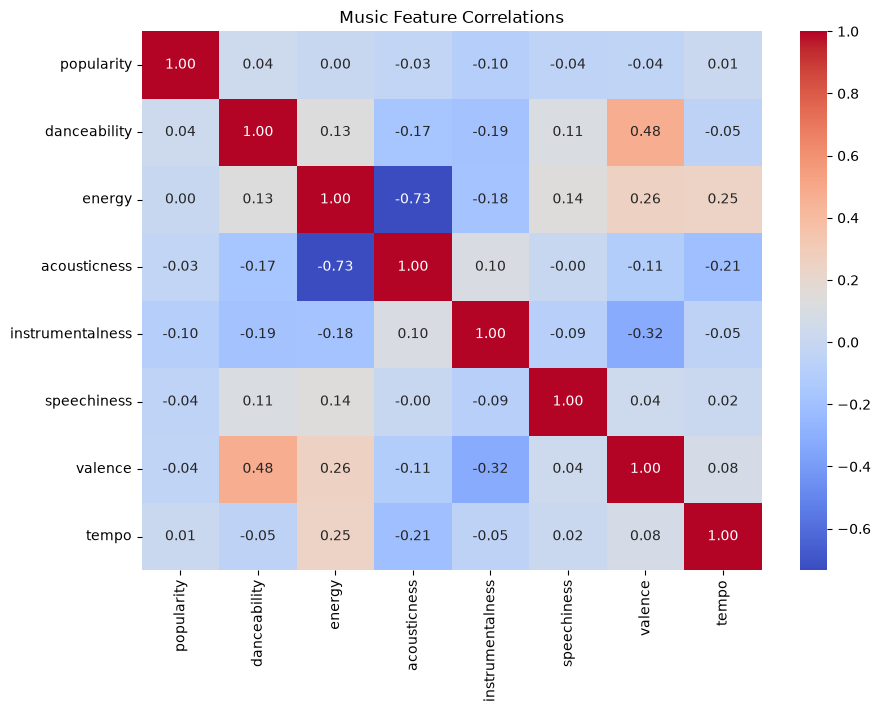

In [6]:
plt.figure(figsize=(10, 7))

sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Music Feature Correlations")
plt.show()

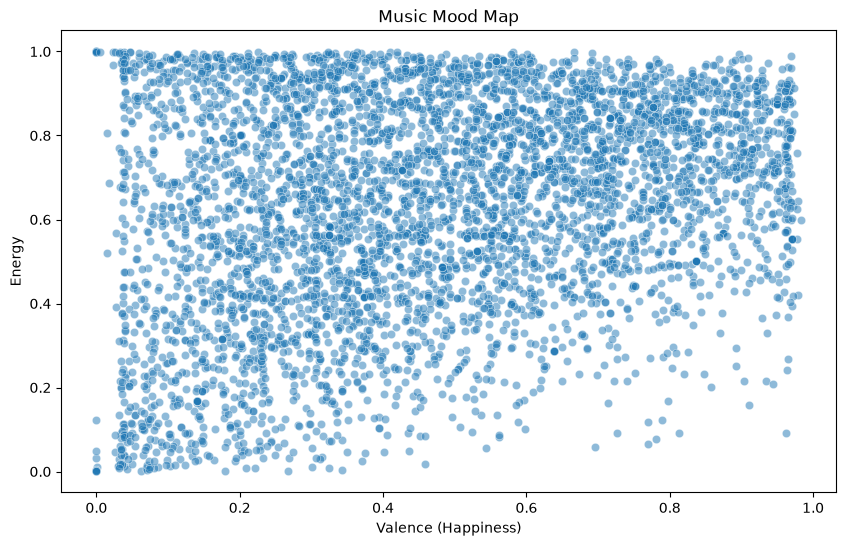

In [7]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(5000),
    x="valence",
    y="energy",
    alpha=0.5
)

plt.title("Music Mood Map")
plt.xlabel("Valence (Happiness)")
plt.ylabel("Energy")

plt.show()

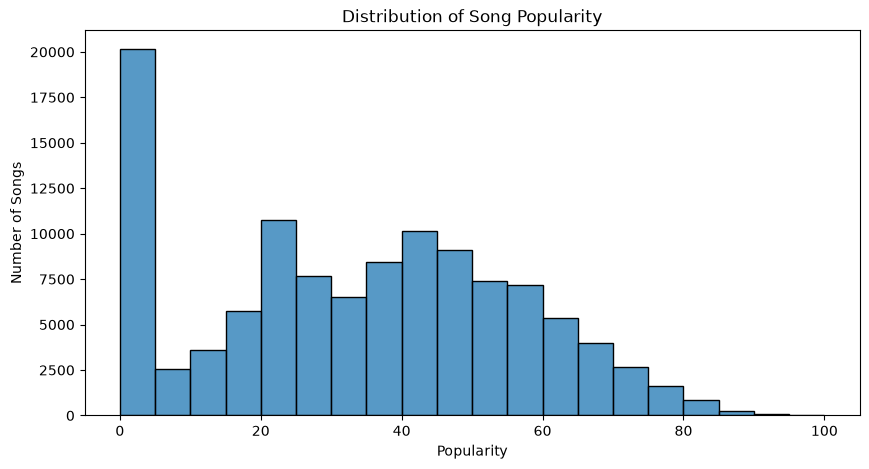

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(df["popularity"], bins=20)

plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

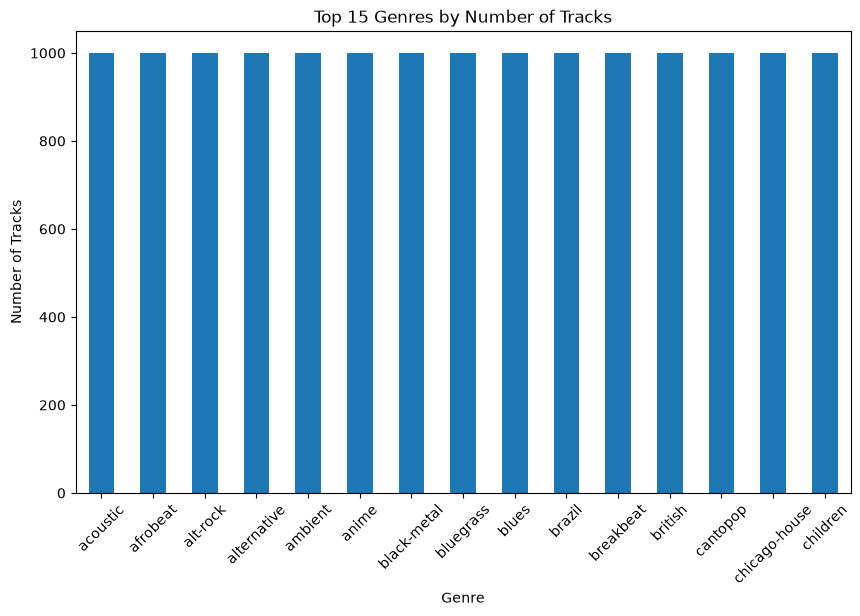

In [9]:
plt.figure(figsize=(10, 6))

df["track_genre"].value_counts().head(15).plot(kind="bar")

plt.title("Top 15 Genres by Number of Tracks")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45)

plt.show()

In [10]:
df.iloc[0]

track_id            5SuOikwiRyPMVoIQDJUgSV
artists                        Gen Hoshino
album_name                          Comedy
track_name                          Comedy
popularity                              73
duration_ms                         230666
explicit                             False
danceability                         0.676
energy                               0.461
key                                      1
loudness                            -6.746
mode                                     0
speechiness                          0.143
acousticness                        0.0322
instrumentalness                  0.000001
liveness                             0.358
valence                              0.715
tempo                               87.917
time_signature                           4
track_genre                       acoustic
Name: 0, dtype: object

In [11]:
df[df["track_name"].str.contains("Shape of You", case=False, na=False)].head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
45459,571K2H9m407zXaFXnpoas1,Andrew Foy,Best Covers,Shape Of You,24,220459,False,0.561,0.284,1,-15.309,0,0.0491,0.791000,0.860000,0.1070,0.825,96.893,4,guitar
55649,27N6lqXxjDiylUqHa84fA6,IndianRaga;Mahesh Raghvan;Vinod Krishnan;Adity...,Shape of You (Carnatic Mix),Shape of You - Abheri - Shudha Dhanyasi - Adi ...,47,170034,False,0.735,0.722,1,-8.373,0,0.0352,0.489000,0.000000,0.3830,0.936,95.967,4,indian
57536,27N6lqXxjDiylUqHa84fA6,IndianRaga;Mahesh Raghvan;Vinod Krishnan;Adity...,Shape of You (Carnatic Mix),Shape of You - Abheri - Shudha Dhanyasi - Adi ...,47,170034,False,0.735,0.722,1,-8.373,0,0.0352,0.489000,0.000000,0.3830,0.936,95.967,4,indie
72803,7hH4dSp71EOv3XS57e8CYu,Our Last Night,Shape of You (Rock),Shape of You - Rock,48,241000,False,0.554,0.959,1,-4.786,0,0.0403,0.000142,0.000504,0.2860,0.349,96.005,4,metalcore
81030,7qiZfU4dY1lWllzX7mPBI3,Ed Sheeran,÷ (Deluxe),Shape of You,86,233712,False,0.825,0.652,1,-3.183,0,0.0802,0.581000,0.000000,0.0931,0.931,95.977,4,pop


In [13]:
def music_dna(song_name):
    song = df[df["track_name"].str.contains(song_name, case=False, na=False)].iloc[0]

    print("🎧 MUSIC DNA")
    print("--------------------")
    print("Song:", song["track_name"])
    print("Artist:", song["artists"])
    print("Genre:", song["track_genre"])
    print()
    print("Energy:", round(song["energy"] * 100), "%")
    print("Danceability:", round(song["danceability"] * 100), "%")
    print("Valence:", round(song["valence"] * 100), "%")
    print("Acousticness:", round(song["acousticness"] * 100), "%")
    print("Instrumentalness:", round(song["instrumentalness"] * 100), "%")
    print("Speechiness:", round(song["speechiness"] * 100), "%")
    print("Tempo:", round(song["tempo"]), "BPM")

In [14]:
music_dna("Shape of You")

🎧 MUSIC DNA
--------------------
Song: Shape Of You
Artist: Andrew Foy
Genre: guitar

Energy: 28 %
Danceability: 56 %
Valence: 82 %
Acousticness: 79 %
Instrumentalness: 86 %
Speechiness: 5 %
Tempo: 97 BPM


In [15]:
dna_features = {
    "Energy": "energy",
    "Danceability": "danceability",
    "Valence": "valence",
    "Acousticness": "acousticness",
    "Instrumentalness": "instrumentalness",
    "Speechiness": "speechiness"
}

In [16]:
def get_music_dna(song_name):
    song = df[df["track_name"].str.contains(song_name, case=False, na=False)].iloc[0]

    dna = {}

    for name, column in dna_features.items():
        dna[name] = round(song[column] * 100, 1)

    return dna

In [17]:
get_music_dna("Shape of You")

{'Energy': np.float64(28.4),
 'Danceability': np.float64(56.1),
 'Valence': np.float64(82.5),
 'Acousticness': np.float64(79.1),
 'Instrumentalness': np.float64(86.0),
 'Speechiness': np.float64(4.9)}

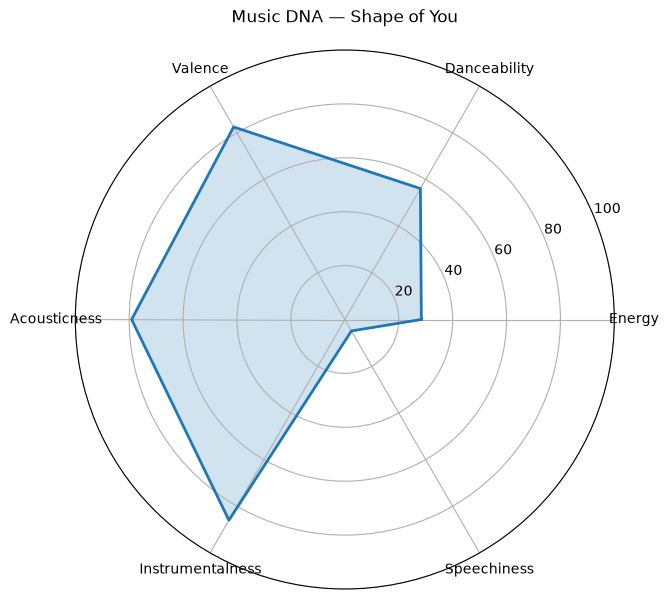

In [18]:
import numpy as np
import matplotlib.pyplot as plt

dna = get_music_dna("Shape of You")

labels = list(dna.keys())
values = list(dna.values())

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
values += values[:1]
angles = np.append(angles, angles[0])

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

ax.plot(angles, values, linewidth=2)
ax.fill(angles, values, alpha=0.2)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)

ax.set_ylim(0, 100)
ax.set_title("Music DNA — Shape of You", pad=20)

plt.show()

In [19]:
def search_song(song_name):
    results = df[df["track_name"].str.contains(song_name, case=False, na=False)]

    return results[["track_name", "artists", "track_genre", "popularity"]].head(10)

In [20]:
search_song("Shape of You")

,track_name,artists,track_genre,popularity
45459,Shape Of You,Andrew Foy,guitar,24
55649,Shape of You - Abheri - Shudha Dhanyasi - Adi ...,IndianRaga;Mahesh Raghvan;Vinod Krishnan;Adity...,indian,47
57536,Shape of You - Abheri - Shudha Dhanyasi - Adi ...,IndianRaga;Mahesh Raghvan;Vinod Krishnan;Adity...,indie,47
72803,Shape of You - Rock,Our Last Night,metalcore,48
81030,Shape of You,Ed Sheeran,pop,86


In [21]:
def search_song(song_name):
    results = df[df["track_name"].str.lower() == song_name.lower()]
    return results[["track_name", "artists", "track_genre", "popularity"]]

In [22]:
search_song("Shape Of You")

,track_name,artists,track_genre,popularity
45459,Shape Of You,Andrew Foy,guitar,24
81030,Shape of You,Ed Sheeran,pop,86


In [23]:
def get_song(song_name):
    results = df[df["track_name"].str.lower() == song_name.lower()]

    if results.empty:
        return None

    song = results.sort_values("popularity", ascending=False).iloc[0]

    return song

In [24]:
song = get_song("Shape Of You")
song[["track_name", "artists", "track_genre", "popularity"]]

track_name     Shape of You
artists          Ed Sheeran
track_genre             pop
popularity               86
Name: 81030, dtype: object

In [25]:
def get_music_dna(song_name):
    song = get_song(song_name)

    if song is None:
        return None

    dna = {}

    for name, column in dna_features.items():
        dna[name] = round(song[column] * 100, 1)

    return dna

In [26]:
get_music_dna("Shape Of You")

{'Energy': np.float64(65.2),
 'Danceability': np.float64(82.5),
 'Valence': np.float64(93.1),
 'Acousticness': np.float64(58.1),
 'Instrumentalness': np.float64(0.0),
 'Speechiness': np.float64(8.0)}

In [29]:
def get_mood(song_name):
    song = get_song(song_name)

    if song is None:
        return "Song not found"

    energy = song["energy"]
    valence = song["valence"]

    if energy >= 0.6 and valence >= 0.6:
        return "Energetic & Happy!"
    elif energy >= 0.6 and valence < 0.6:
        return "Energetic & Intense!"
    elif energy < 0.6 and valence >= 0.6:
        return "Calm & Happy"
    else:
        return "Calm & Melancholic"

In [30]:
get_mood("Shape Of You")

'Energetic & Happy!'

In [31]:
def classify_mood(row):
    energy = row["energy"]
    valence = row["valence"]

    if energy >= 0.6 and valence >= 0.6:
        return "Energetic & Happy"
    elif energy >= 0.6 and valence < 0.6:
        return "Energetic & Intense"
    elif energy < 0.6 and valence >= 0.6:
        return "Calm & Happy"
    else:
        return "Calm & Melancholic"

df["mood"] = df.apply(classify_mood, axis=1)

In [32]:
df["mood"].value_counts()

mood
Energetic & Intense    40517
Calm & Melancholic     34694
Energetic & Happy      28872
Calm & Happy            9916
Name: count, dtype: int64

In [33]:
hidden_gems = df[
    (df["popularity"] < 40) &
    (df["energy"] > 0.6) &
    (df["danceability"] > 0.6) &
    (df["valence"] > 0.5)
]

hidden_gems = hidden_gems.sort_values(
    ["danceability", "energy"],
    ascending=False
)

hidden_gems[["track_name", "artists", "track_genre", "popularity"]].head(10)

,track_name,artists,track_genre,popularity
66575,Medicaid Baby,That Girl Lay Lay,kids,10
13353,Bitches,dj funk,chicago-house,10
66792,"Featuring Mixx Master Lee, Red Rum & J. Smoov ...",Mixx Master Lee,kids,7
66061,Go Lay Lay Go,That Girl Lay Lay,kids,21
13168,Most Wanted,Fast Eddie,chicago-house,12
60991,Betray Di Gaza Boss,Vybz Kartel;Tommy Lee,j-dance,18
66973,Letter Q Song,Have Fun Teaching,kids,8
66587,Cha Cha Slide,Line Dances,kids,10
66847,Cha Cha Slide,Chicken Dance Mix DJ's,kids,8
66890,Cha Cha Slide,Electric Slide Dance Party DJ's,kids,8


In [35]:
recommendation_features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "speechiness",
    "valence",
    "tempo"
]

In [38]:
import numpy as np
def recommend_songs(song_name, n=5):
    song = get_song(song_name)

    if song is None:
        return "Song not found"

    features = df[recommendation_features].values
    target = song[recommendation_features].values

    distances = np.sqrt(((features - target) ** 2).sum(axis=1))

    indices = np.argsort(distances)

    recommendations = df.iloc[indices]

    recommendations = recommendations[
        recommendations["track_name"].str.lower() != song_name.lower()
    ]

    return recommendations[
        ["track_name", "artists", "track_genre", "popularity"]
    ].head(n)

In [39]:
recommend_songs("Shape Of You")

TypeError: loop of ufunc does not support argument 0 of type numpy.float64 which has no callable sqrt method

In [40]:
import numpy as npp
print(type(npp))

<class 'module'>


In [45]:
recommendation_features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "speechiness",
    "valence",
    "tempo"
]

feature_data = df[recommendation_features].astype(float)

feature_min = feature_data.min()
feature_max = feature_data.max()

normalized_features = (feature_data - feature_min) / (feature_max - feature_min)

In [52]:
def recommend_songs(song_name, n=5):
    song = get_song(song_name)

    if song is None:
        return "Song not found"

    genre = song["track_genre"]

    candidates = df[
        (df["track_genre"] == genre) &
        (df["popularity"] >= 60)
    ].copy()

    candidates = candidates[
        candidates["track_name"].str.lower() != song_name.lower()
    ]

    features = [
        "danceability",
        "energy",
        "acousticness",
        "instrumentalness",
        "speechiness",
        "valence"
    ]

    target = song[features].astype(float).values
    values = candidates[features].astype(float).values

    distance = ((values - target) ** 2).sum(axis=1)

    candidates["similarity"] = 1 / (1 + distance)

    candidates["score"] = (
        candidates["similarity"] * 0.4 +
        (candidates["popularity"] / 100) * 0.6
    )

    candidates = candidates.sort_values("score", ascending=False)

    return candidates[
        ["track_name", "artists", "track_genre", "popularity"]
    ].head(n)

In [57]:
recommend_songs("Shape of You")

,track_name,artists,track_genre,popularity
81023,Left and Right (Feat. Jung Kook of BTS),Charlie Puth;Jung Kook;BTS,pop,92
81099,Calm Down (with Selena Gomez),Rema;Selena Gomez,pop,92
81051,As It Was,Harry Styles,pop,95
81191,There's Nothing Holdin' Me Back,Shawn Mendes,pop,86
81173,I Ain't Worried,OneRepublic,pop,96


In [58]:
def get_hidden_gems(n=10):
    gems = df[
        (df["popularity"] >= 20) &
        (df["popularity"] < 50) &
        (df["energy"] >= 0.6) &
        (df["danceability"] >= 0.6) &
        (df["valence"] >= 0.5)
    ].copy()

    gems["gem_score"] = (
        gems["energy"] * 0.3 +
        gems["danceability"] * 0.3 +
        gems["valence"] * 0.2 +
        (gems["popularity"] / 100) * 0.2
    )

    gems = gems.sort_values("gem_score", ascending=False)

    return gems[
        ["track_name", "artists", "track_genre", "popularity"]
    ].head(n)

In [59]:
get_hidden_gems()

,track_name,artists,track_genre,popularity
77509,Combo De Boca (Tô Mal),Leo Santana,pagode,46
37734,Combo De Boca (Tô Mal),Leo Santana,funk,46
111635,Night over Manaus,Boozoo Bajou,trip-hop,49
69282,Boom Boom Robot Da,Yogi B;Keerthi Sagathia;Shweta Mohan;Tanvi Shah,malay,34
89931,PAL PARY,Kail BRL;NvshoFlight,reggaeton,39
35516,Deixa o Povo Dançar,Alemão Do Forró,forro,40
37738,TIPO HARIEL - SEI QUE E RARIDADE -,DJ BRUNO PRADO,funk,44
21765,Bank Alert,P-Square,dancehall,45
78265,Besoffe vör Glück,Brings,party,36
57376,Kangna Tera Ni,Lumber,indie,47


In [60]:
def compare_songs(song1, song2):
    a = get_song(song1)
    b = get_song(song2)

    if a is None or b is None:
        return "One or both songs were not found"

    return pd.DataFrame({
        "Feature": [
            "Popularity",
            "Energy",
            "Danceability",
            "Valence",
            "Acousticness",
            "Instrumentalness",
            "Speechiness"
        ],
        song1: [
            a["popularity"],
            a["energy"],
            a["danceability"],
            a["valence"],
            a["acousticness"],
            a["instrumentalness"],
            a["speechiness"]
        ],
        song2: [
            b["popularity"],
            b["energy"],
            b["danceability"],
            b["valence"],
            b["acousticness"],
            b["instrumentalness"],
            b["speechiness"]
        ]
    })

In [61]:
compare_songs("Shape Of You", "Blinding Lights")

,Feature,Shape Of You,Blinding Lights
0,Popularity,86.0000,91.000000
1,Energy,0.6520,0.730000
2,Danceability,0.8250,0.514000
3,Valence,0.9310,0.334000
4,Acousticness,0.5810,0.001460
5,Instrumentalness,0.0000,0.000095
6,Speechiness,0.0802,0.059800


In [62]:
def get_mood_songs(mood, n=10):
    songs = df[
        (df["mood"] == mood) &
        (df["popularity"] >= 40)
    ].copy()

    songs = songs.sort_values("popularity", ascending=False)

    return songs[
        ["track_name", "artists", "track_genre", "popularity"]
    ].head(n)

In [63]:
get_mood_songs("Energetic & Happy")

,track_name,artists,track_genre,popularity
89410,La Bachata,Manuel Turizo,reggaeton,98
67355,La Bachata,Manuel Turizo,latin,98
68302,La Bachata,Manuel Turizo,latino,98
88409,La Bachata,Manuel Turizo,reggae,98
91002,I Ain't Worried,OneRepublic,rock,96
81173,I Ain't Worried,OneRepublic,pop,96
78999,I Ain't Worried,OneRepublic,piano,96
81051,As It Was,Harry Styles,pop,95
20850,CUFF IT,Beyoncé,dance,93
81099,Calm Down (with Selena Gomez),Rema;Selena Gomez,pop,92


In [64]:
get_mood_songs("Calm & Melancholic")

,track_name,artists,track_genre,popularity
20001,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,dance,100
81050,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,pop,100
67558,Efecto,Bad Bunny,latin,96
68358,Efecto,Bad Bunny,latino,96
88450,Efecto,Bad Bunny,reggae,95
89450,Efecto,Bad Bunny,reggaeton,95
81101,Glimpse of Us,Joji,pop,94
67699,Neverita,Bad Bunny,latin,93
15013,Another Love,Tom Odell,chill,93
81860,Another Love,Tom Odell,pop,93
